# Closed-set vs open-vocabulary detection: a COCO-style benchmark

Notebook 01 showed what the detectors do on a few scenes. This notebook **measures** them:

1. **COCO, 80 classes** (fixed-seed 200-image subset of val2017). This is home ground for the
   closed-set YOLO26-s, which was trained on COCO train2017. The open-vocabulary models get the
   80 class names as text prompts and are evaluated **zero-shot** (no COCO fine-tuning).
2. **Novel classes**: the Ultralytics *african-wildlife* validation split (225 images).
   *Elephant* and *zebra* are COCO classes; **buffalo** and **rhino** are not, so the closed-set
   model cannot name them.
3. **Prompt wording**: the same four wildlife classes written four different ways.
4. **Operating points**: precision, recall and F1 as a function of the score threshold, because
   a robot has to commit to one threshold while AP averages over all of them.

Plus latency and peak VRAM per model on the same GPU.

**What you'll learn:** how COCO AP is computed with `pycocotools`, how to evaluate a text-prompted
detector with a fixed class list, how to read a speed/accuracy trade-off, and where zero-shot
comparisons mislead (training-data overlap, calibration).

**How the numbers were produced:** the heavy part (7 models x 425 images, plus the prompt study)
runs in `scripts/eval_detectors.py` on an RTX 5060 Laptop GPU (8 GB) and writes small JSON files
to `projects/04_open_vocab_detection/results/`. Each file also stores its wall-clock time
(`eval_s`); the slowest run, SAM 3 on COCO with 80 prompts, took 442 s. This notebook loads the
files, and section 2 re-runs the evaluation pipeline live on 25 images so you can see every step.

**Prerequisites:** notebook 01; the AP/PR-curve basics from project 03.

## Setup

In [1]:
# --- Setup: imports, device, paths, style ---
import os
import sys

os.environ["YOLO_AUTOINSTALL"] = "false"  # never let Ultralytics pip-install at runtime
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cvlab import device as cvdevice
from cvlab import io as cvio
from cvlab import viz

PROJECT = "04_open_vocab_detection"
sys.path.insert(0, str(cvio.project_dir(PROJECT) / "scripts"))
import ovd  # noqa: E402

device = cvdevice.setup(seed=0)
viz.set_style()
RESULTS = cvio.project_dir(PROJECT) / "results"
print("results:", sorted(p.name for p in RESULTS.glob("*.json")))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
results: ['coco_gdino_t.json', 'coco_llmdet_t.json', 'coco_omdet_t.json', 'coco_owlv2_b.json', 'coco_sam3.json', 'coco_yolo26s.json', 'coco_yoloe26s.json', 'wildlife_gdino_t.json', 'wildlife_llmdet_t.json', 'wildlife_omdet_t.json', 'wildlife_owlv2_b.json', 'wildlife_prompt_study.json', 'wildlife_sam3.json', 'wildlife_yolo26s.json', 'wildlife_yoloe26s.json']


## 1. How COCO AP works (and what "zero-shot" means here)

For one class, detections from all images are sorted by score. Each one is a true positive if it
matches a still-unmatched ground-truth box with $\mathrm{IoU} \ge \tau$. This gives a
precision-recall curve. The precision is made monotone ($\tilde p(r) = \max_{r' \ge r} p(r')$)
and sampled at 101 recall points:

$$\mathrm{AP}_\tau = \frac{1}{101}\sum_{r \in \{0, 0.01, \dots, 1\}} \tilde p(r), \qquad
\mathrm{AP} = \frac{1}{10}\sum_{\tau \in \{0.5, 0.55, \dots, 0.95\}} \mathrm{AP}_\tau,$$

averaged over classes. At most 100 detections per image are scored, and `iscrowd` regions are
ignored. AP rewards a good **ranking** of detections and is independent of any single threshold.

**Caveats for an open-vocabulary comparison.**
* *Zero-shot is not unseen.* Objects365 (used by YOLOE, Grounding DINO, LLMDet, OmDet-Turbo)
  contains all 80 COCO categories, and the GoldG grounding data includes Visual Genome / GQA
  images, many of which are COCO images. "Zero-shot" here means **no training on COCO's label
  set and annotations**, not "never saw these concepts".
* The closed-set YOLO26-s was trained on exactly this label set (train2017), so it is the
  in-domain reference.
* 200 images is a small sample (about 1.4k objects). Differences of 1-2 AP points are within noise.

## 2. The evaluation pipeline, live on 25 images

The same code `eval_detectors.py` runs on the full 200-image subset: set the vocabulary to the 80
COCO names, keep up to 100 detections per image with score >= 0.01 (low, so the PR curve reaches
high recall), convert to COCO results JSON (`bbox` = `[x, y, w, h]`), then run `COCOeval`.

In [2]:
# --- Live mini-evaluation: YOLOE-26-s on the first 25 images of the COCO subset ---
gt_json = cvio.load_json(cvio.data_dir("coco", "annotations", "instances_val2017_ovd200.json"))
coco_gt = ovd.coco_from_dict(gt_json)
cat_ids = sorted(coco_gt.getCatIds())
names = [coco_gt.cats[c]["name"] for c in cat_ids]  # the 80 prompts, in category-id order
images = sorted((im["id"], im["file_name"]) for im in gt_json["images"])[:25]

det = ovd.load_detector("yoloe26s").set_vocabulary(names)
results = []
for img_id, fname in images:
    d = det.predict(cvio.read_image(cvio.data_dir("coco", "val2017", fname)), min_score=0.01, max_det=100)
    results += ovd.detections_to_coco(d, img_id, cat_ids)
ovd.free_detector(det)
print("one result entry:", results[0])
mini = ovd.coco_evaluate(coco_gt, results, [i for i, _ in images])
print({k: round(v, 3) for k, v in mini.items() if isinstance(v, float)})

one result entry: {'image_id': 1425, 'category_id': 47, 'bbox': [496.25, 201.75, 143.75, 175.0], 'score': 0.77051}
{'AP': 0.489, 'AP50': 0.67, 'AP75': 0.543, 'APs': 0.382, 'APm': 0.49, 'APl': 0.537, 'AR100': 0.572}


On 25 images the numbers are noisy. The full-subset results below come from the same function
over 200 images. Now load every model's result file.

In [3]:
# --- Load all results written by scripts/eval_detectors.py ---
ORDER = ["yolo26s", "yoloe26s", "gdino_t", "llmdet_t", "owlv2_b", "omdet_t", "sam3"]
R = {ds: {k: cvio.load_json(RESULTS / f"{ds}_{k}.json") for k in ORDER if (RESULTS / f"{ds}_{k}.json").exists()}
     for ds in ("coco", "wildlife")}
prompt_study = cvio.load_json(RESULTS / "wildlife_prompt_study.json")
LABEL = {k: ovd.MODEL_INFO[k][0] for k in ORDER}
COLOR = {k: viz.color(i, unit=True) for i, k in enumerate(ORDER)}
coco = pd.DataFrame([{"model": LABEL[k], **r["metrics"], "latency_ms": r["latency_ms"]["mean_ms"],
                      "peak_vram_mb": r["peak_vram_mb"], "weights_vram_mb": r["weights_vram_mb"]}
                     for k, r in R["coco"].items()]).set_index("model")
print("hardware:", R["coco"]["yolo26s"]["hardware"], "| torch", R["coco"]["yolo26s"]["torch"])
coco[["AP", "AP50", "AP75", "APs", "APm", "APl", "AR100", "latency_ms", "peak_vram_mb"]].round(3)

hardware: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB) | torch 2.11.0+cu128


,AP,AP50,AP75,APs,APm,APl,AR100,latency_ms,peak_vram_mb
model,,,,,,,,,
YOLO26-s (closed-set),0.519,0.683,0.552,0.321,0.523,0.745,0.625,5.05,71.3
YOLOE-26-s,0.404,0.560,0.416,0.240,0.438,0.596,0.519,29.07,497.4
Grounding DINO-T,0.517,0.668,0.545,0.409,0.565,0.684,0.726,188.28,1160.7
LLMDet-T,0.592,0.748,0.632,0.436,0.618,0.784,0.765,184.64,1162.9
OWLv2-B/16,0.540,0.736,0.585,0.404,0.557,0.720,0.684,73.74,405.7
OmDet-Turbo-T,0.461,0.615,0.484,0.307,0.499,0.705,0.635,34.15,342.3
SAM 3,0.586,0.776,0.629,0.407,0.639,0.782,0.726,2189.44,2231.2


## Results

### 3. COCO: closed-set vs zero-shot open vocabulary

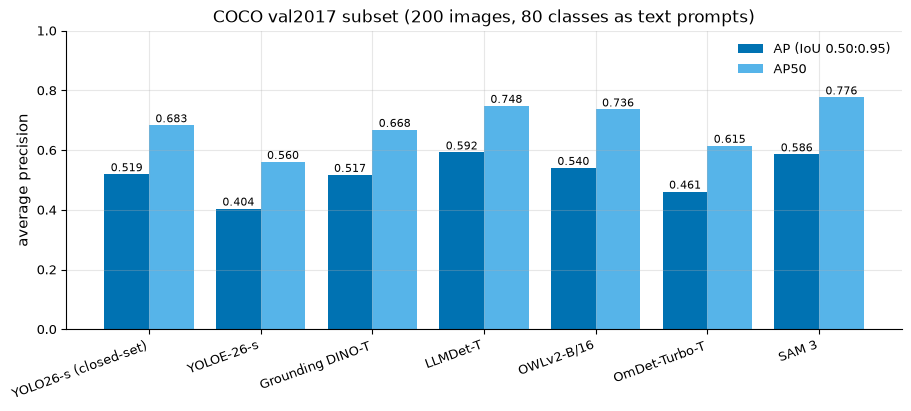

In [4]:
# --- Figure: COCO AP and AP50 per model ---
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(coco))
ax.bar(x - 0.2, coco.AP, 0.4, label="AP (IoU 0.50:0.95)", color=viz.color(0, unit=True))
ax.bar(x + 0.2, coco.AP50, 0.4, label="AP50", color=viz.color(4, unit=True))
for xi, (a, b) in enumerate(zip(coco.AP, coco.AP50)):
    ax.text(xi - 0.2, a + 0.01, f"{a:.3f}", ha="center", fontsize=8)
    ax.text(xi + 0.2, b + 0.01, f"{b:.3f}", ha="center", fontsize=8)
ax.set_xticks(x, coco.index, rotation=20, ha="right")
ax.set_ylabel("average precision")
ax.set_ylim(0, 1)
ax.set_title("COCO val2017 subset (200 images, 80 classes as text prompts)")
ax.legend()
viz.savefig(fig, PROJECT, "coco_ap")
plt.show()

Precision-recall curves at IoU 0.5 (averaged over the classes present in the subset) show
*where* the models differ: the start of the curve reflects the precision of the most confident
detections, and the end reflects how far down the ranking each model still finds objects.

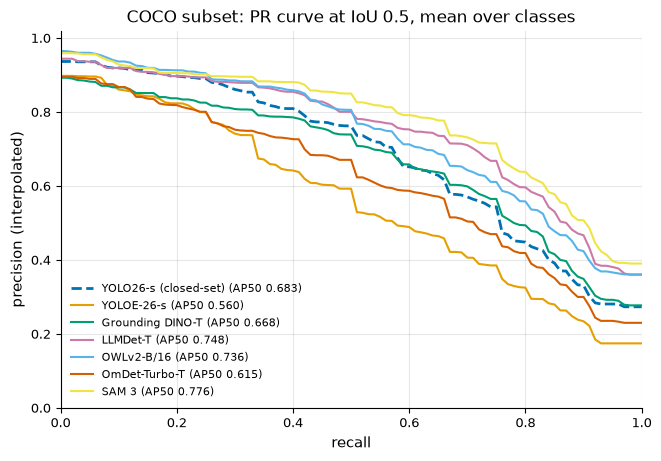

In [5]:
# --- Figure: PR curves at IoU 0.5 ---
rec = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k, r in R["coco"].items():
    ax.plot(rec, r["pr_curve_iou50"], label=f"{LABEL[k]} (AP50 {r['metrics']['AP50']:.3f})", color=COLOR[k],
            lw=2 if k == "yolo26s" else 1.5, ls="--" if k == "yolo26s" else "-")
ax.set_xlabel("recall")
ax.set_ylabel("precision (interpolated)")
ax.set_title("COCO subset: PR curve at IoU 0.5, mean over classes")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(fontsize=8)
viz.savefig(fig, PROJECT, "coco_pr_curves")
plt.show()

Per-class AP shows **which** COCO classes zero-shot prompting struggles with. Each point is one
class: x = closed-set YOLO26-s, y = the best open-vocabulary model on COCO. Points below the
diagonal are classes where the label-set-specific training still wins.

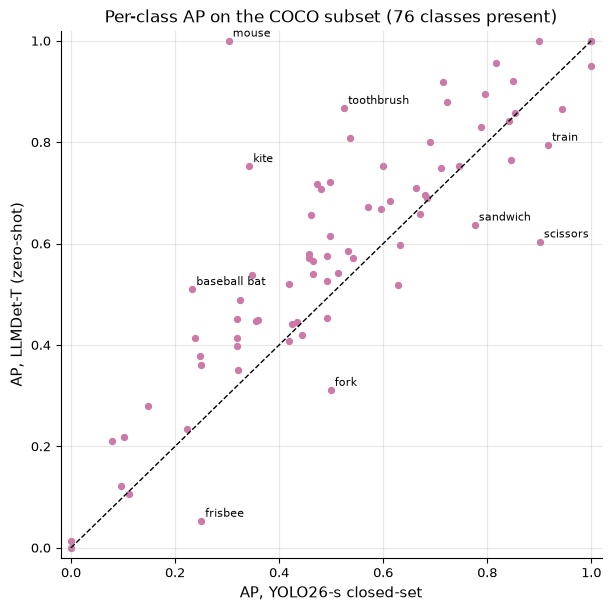

largest deficits of the open model: {'scissors': -0.297, 'frisbee': -0.197, 'fork': -0.188, 'sandwich': -0.139, 'train': -0.122}
largest gains of the open model: {'baseball bat': 0.277, 'toothbrush': 0.342, 'kite': 0.41, 'mouse': 0.697}


In [6]:
# --- Figure: per-class AP, closed-set vs best open-vocabulary model ---
open_keys = [k for k in R["coco"] if k != "yolo26s"]
best_open = max(open_keys, key=lambda k: R["coco"][k]["metrics"]["AP"])
pc_closed = pd.Series(R["coco"]["yolo26s"]["per_class_AP"]).dropna()
pc_open = pd.Series(R["coco"][best_open]["per_class_AP"]).reindex(pc_closed.index)
gap = (pc_open - pc_closed).sort_values()
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(pc_closed, pc_open, s=18, color=COLOR[best_open])
ax.plot([0, 1], [0, 1], "k--", lw=1)
for name in list(gap.index[:5]) + list(gap.index[-4:]):
    ax.annotate(name, (pc_closed[name], pc_open[name]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("AP, YOLO26-s closed-set")
ax.set_ylabel(f"AP, {LABEL[best_open]} (zero-shot)")
ax.set_title(f"Per-class AP on the COCO subset ({len(pc_closed)} classes present)")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
viz.savefig(fig, PROJECT, "coco_per_class")
plt.show()
print("largest deficits of the open model:", gap.head(5).round(3).to_dict())
print("largest gains of the open model:", gap.tail(4).round(3).to_dict())

### 4. Speed vs accuracy

End-to-end latency (pre-processing, network, post-processing; batch 1; CUDA-synchronised) on
the first COCO image with the full 80-class vocabulary. Bubble area is proportional to peak
VRAM. The vocabulary size matters a lot for SAM 3, which runs its fusion decoder once **per
prompt**: 80 classes means 80 decoder passes per image.

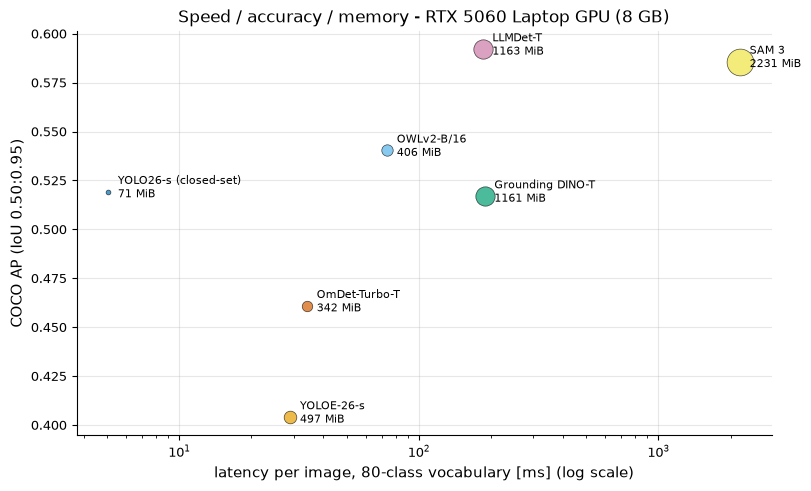

In [7]:
# --- Figure: AP vs latency (bubble = peak VRAM) ---
fig, ax = plt.subplots(figsize=(8, 4.8))
for k, r in R["coco"].items():
    ax.scatter(r["latency_ms"]["mean_ms"], r["metrics"]["AP"], s=r["peak_vram_mb"] / 6, color=COLOR[k],
               alpha=0.7, edgecolor="k", lw=0.5)
    ax.annotate(f"{LABEL[k]}\n{r['peak_vram_mb']:.0f} MiB", (r["latency_ms"]["mean_ms"], r["metrics"]["AP"]),
                fontsize=8, xytext=(7, -4), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("latency per image, 80-class vocabulary [ms] (log scale)")
ax.set_ylabel("COCO AP (IoU 0.50:0.95)")
ax.set_title("Speed / accuracy / memory - RTX 5060 Laptop GPU (8 GB)")
viz.savefig(fig, PROJECT, "speed_accuracy")
plt.show()

### 5. Novel classes: african-wildlife

AP per class on 225 validation images. The closed-set model gets the same four names. It can
only map *elephant* and *zebra* to its own classes, so **buffalo and rhino score 0 by
construction**. The open models get all four names as prompts.

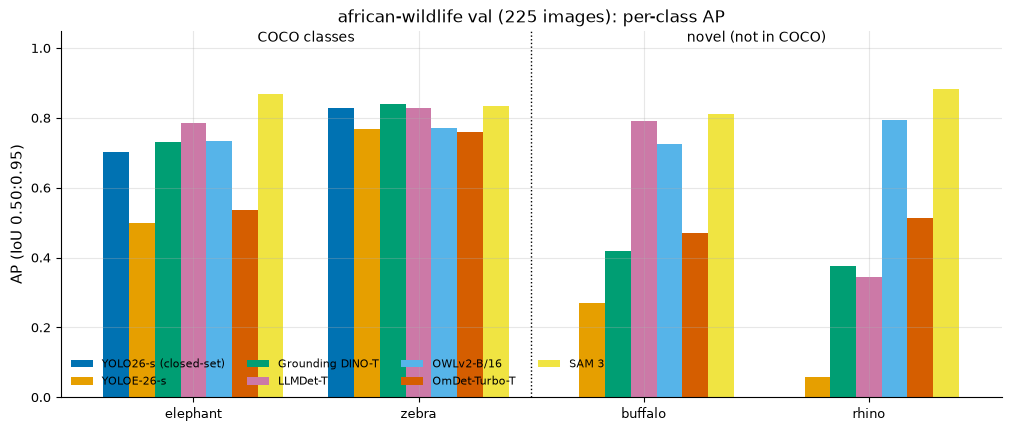

In [8]:
# --- Figure: per-class AP on african-wildlife (base vs novel classes) ---
WL = ["elephant", "zebra", "buffalo", "rhino"]
wl = pd.DataFrame({LABEL[k]: r["per_class_AP"] for k, r in R["wildlife"].items()}).T[WL]
fig, ax = plt.subplots(figsize=(10, 4.2))
w = 0.8 / len(wl)
for i, (k, (m, row)) in enumerate(zip(R["wildlife"], wl.iterrows())):
    ax.bar(np.arange(4) + (i - (len(wl) - 1) / 2) * w, row.values, w, label=m, color=COLOR[k])
ax.axvline(1.5, color="k", lw=1, ls=":")
ax.text(0.5, 0.97, "COCO classes", ha="center", transform=ax.get_xaxis_transform())
ax.text(2.5, 0.97, "novel (not in COCO)", ha="center", transform=ax.get_xaxis_transform())
ax.set_xticks(range(4), WL)
ax.set_ylabel("AP (IoU 0.50:0.95)")
ax.set_ylim(0, 1.05)
ax.set_title("african-wildlife val (225 images): per-class AP")
ax.legend(fontsize=8, ncols=4, loc="lower left")
viz.savefig(fig, PROJECT, "wildlife_per_class")
plt.show()

What *does* the closed-set model say when it sees a buffalo or a rhino? For each ground-truth
box, the label of the best-overlapping YOLO26-s detection (IoU >= 0.5, score >= 0.25, all 80
COCO classes allowed), or *missed*.

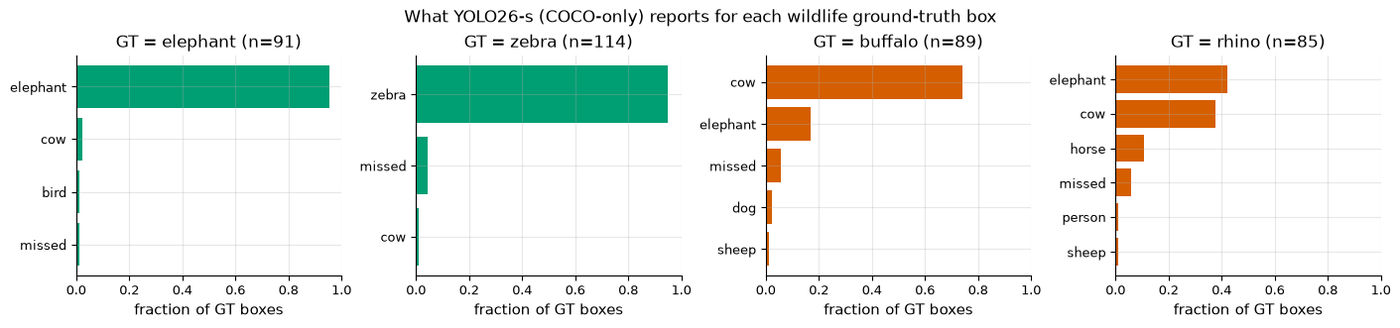

In [9]:
# --- Figure: closed-set "confusion" for animals it has no class for ---
conf = R["wildlife"]["yolo26s"]["closed_set_confusion"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=False)
for ax, cls in zip(axes, WL):
    c = pd.Series(conf[cls]).sort_values(ascending=True).tail(6)
    ax.barh(c.index, c.values / sum(conf[cls].values()), color=viz.color(5 if cls in ("buffalo", "rhino") else 2, unit=True))
    ax.set_xlabel("fraction of GT boxes")
    ax.set_title(f"GT = {cls} (n={sum(conf[cls].values())})")
    ax.set_xlim(0, 1)
fig.suptitle("What YOLO26-s (COCO-only) reports for each wildlife ground-truth box")
viz.savefig(fig, PROJECT, "closed_set_confusion")
plt.show()

Qualitative check on stored detections (score >= 0.1, top 30) for two validation images:
the closed-set model next to the best open-vocabulary model on the novel classes.

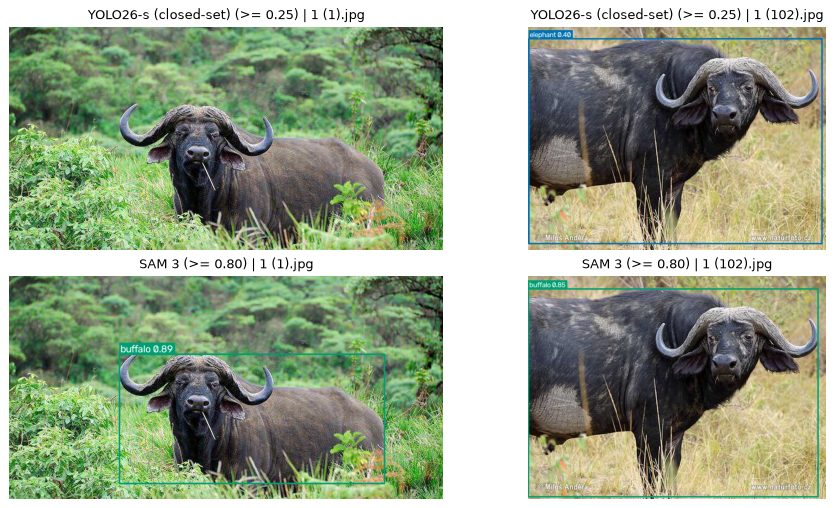

In [10]:
# --- Figure: stored detections on wildlife images, closed-set vs best novel-class model ---
novel_ap = {k: np.mean([r["per_class_AP"]["buffalo"], r["per_class_AP"]["rhino"]]) for k, r in R["wildlife"].items()}
best_novel = max(novel_ap, key=novel_ap.get)
img_dir = cvio.data_dir("ultralytics", "african-wildlife", "images", "val")
ids = list(R["wildlife"]["yolo26s"]["showcase"])[:2]
panels, titles = [], []
for k in ["yolo26s", best_novel]:
    for i in ids:
        s = R["wildlife"][k]["showcase"][i]
        thr = 0.25 if k == "yolo26s" else max(0.25, R["wildlife"][k]["f1_curve"]["best_threshold"])
        keep = [j for j, sc in enumerate(s["scores"]) if sc >= thr]
        img = cvio.read_image(img_dir / s["file"])
        panels.append(viz.draw_boxes(img, np.array(s["boxes"])[keep], [s["labels"][j] for j in keep],
                                     [s["scores"][j] for j in keep], [WL.index(s["labels"][j]) for j in keep]))
        titles.append(f"{LABEL[k]} (>= {thr:.2f}) | {s['file']}")
fig = viz.show_images(panels, titles, ncols=2, size=5)
ovd.show_jpeg(fig)  # photo grid -> JPEG output to keep the notebook small

### 6. Prompt wording

The same four classes, written four ways, evaluated on the full wildlife validation split. All
prompts are sent verbatim (no template). This measures how much the wording alone changes AP.

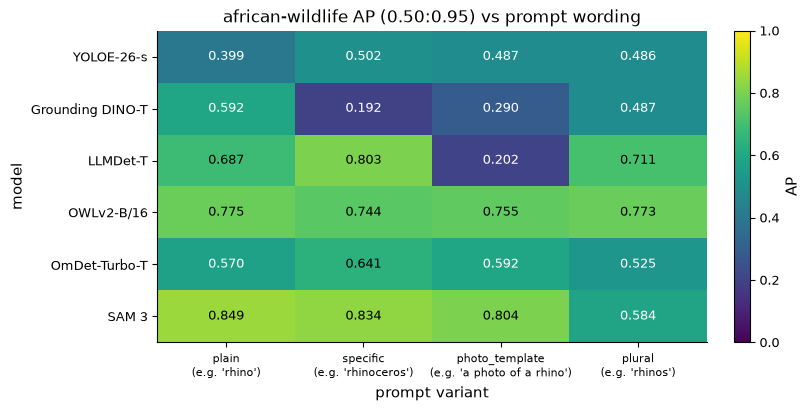

In [11]:
# --- Figure: AP by prompt variant (heatmap) ---
variants = ["plain", "specific", "photo_template", "plural"]
ps = pd.DataFrame({v: {prompt_study[k]["label"]: prompt_study[k][v]["AP"] for k in prompt_study} for v in variants})
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(ps.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
for (r, c), v in np.ndenumerate(ps.values):
    ax.text(c, r, f"{v:.3f}", ha="center", va="center", fontsize=9, color="white" if v < 0.6 else "black")
example = {v: ", ".join(prompt_study["gdino_t"][v]["prompts"][2:3]) for v in variants}
ax.set_xticks(range(len(variants)), [f"{v}\n(e.g. '{example[v]}')" for v in variants], fontsize=8)
ax.set_yticks(range(len(ps)), ps.index)
ax.set_xlabel("prompt variant")
ax.set_ylabel("model")
ax.set_title("african-wildlife AP (0.50:0.95) vs prompt wording")
ax.grid(False)
fig.colorbar(im, ax=ax, label="AP")
viz.savefig(fig, PROJECT, "prompt_study")
plt.show()

### 7. Operating points: F1 vs score threshold

AP integrates over all thresholds. A deployed detector uses one threshold, and **raw scores mean
different things for different models**: a 0.3 from Grounding DINO is not a 0.3 from OWLv2.
The curves show micro-averaged precision/recall/F1 at IoU 0.5 on the COCO subset. The
F1-optimal threshold of each model is marked; these are the thresholds used in notebooks 01
and 03.

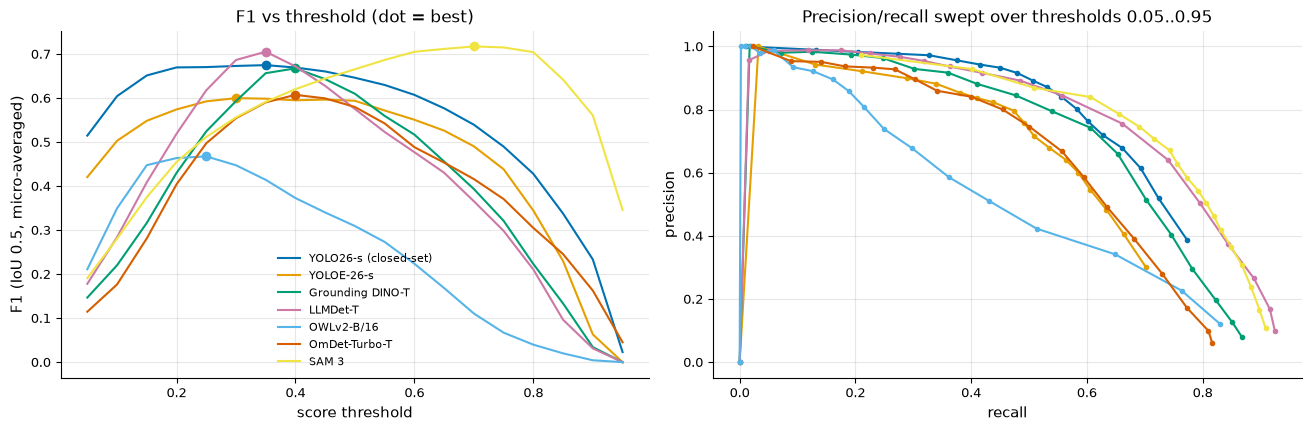

In [12]:
# --- Figure: F1 vs threshold per model (COCO subset) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for k, r in R["coco"].items():
    f = r["f1_curve"]
    axes[0].plot(f["thresholds"], f["f1"], color=COLOR[k], label=LABEL[k])
    axes[0].plot(f["best_threshold"], f["best_f1"], "o", color=COLOR[k])
    axes[1].plot(f["recall"], f["precision"], color=COLOR[k], marker=".", label=LABEL[k])
axes[0].set_xlabel("score threshold")
axes[0].set_ylabel("F1 (IoU 0.5, micro-averaged)")
axes[0].set_title("F1 vs threshold (dot = best)")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision/recall swept over thresholds 0.05..0.95")
axes[0].legend(fontsize=8)
viz.savefig(fig, PROJECT, "f1_thresholds")
plt.show()

### Summary table

All numbers below are copied from the result JSON files (single run, RTX 5060 Laptop GPU 8 GB,
fp16 / bf16 for SAM 3, batch 1).

In [13]:
# --- Summary table of every measured number ---
rows = []
for k in ORDER:
    c, w = R["coco"].get(k), R["wildlife"].get(k)
    if c is None or w is None:
        continue
    rows.append({
        "model": LABEL[k], "type": ovd.MODEL_INFO[k][1],
        "COCO AP": round(c["metrics"]["AP"], 3), "COCO AP50": round(c["metrics"]["AP50"], 3),
        "wildlife AP": round(w["metrics"]["AP"], 3),
        "AP base (elephant, zebra)": round(np.mean([w["per_class_AP"]["elephant"], w["per_class_AP"]["zebra"]]), 3),
        "AP novel (buffalo, rhino)": round(np.mean([w["per_class_AP"]["buffalo"], w["per_class_AP"]["rhino"]]), 3),
        "latency 80 cls [ms]": c["latency_ms"]["mean_ms"], "latency 4 cls [ms]": w["latency_ms"]["mean_ms"],
        "peak VRAM [MiB]": max(c["peak_vram_mb"], w["peak_vram_mb"]),
        "F1-best thr (COCO)": c["f1_curve"]["best_threshold"], "best F1 (COCO)": round(c["f1_curve"]["best_f1"], 3),
    })
summary = pd.DataFrame(rows).set_index("model")
summary

,type,COCO AP,COCO AP50,wildlife AP,"AP base (elephant, zebra)","AP novel (buffalo, rhino)",latency 80 cls [ms],latency 4 cls [ms],peak VRAM [MiB],F1-best thr (COCO),best F1 (COCO)
model,,,,,,,,,,,
YOLO26-s (closed-set),closed,0.519,0.683,0.383,0.765,0.000,5.05,4.78,71.3,0.35,0.675
YOLOE-26-s,open,0.404,0.560,0.399,0.634,0.164,29.07,10.91,497.4,0.30,0.600
Grounding DINO-T,open,0.517,0.668,0.592,0.786,0.397,188.28,183.09,1160.7,0.40,0.667
LLMDet-T,open,0.592,0.748,0.687,0.807,0.567,184.64,180.11,1162.9,0.35,0.705
OWLv2-B/16,open,0.540,0.736,0.755,0.751,0.759,73.74,65.45,406.8,0.25,0.467
OmDet-Turbo-T,open,0.461,0.615,0.570,0.648,0.492,34.15,26.77,342.3,0.40,0.607
SAM 3,open,0.586,0.776,0.849,0.851,0.847,2189.44,439.56,2231.2,0.70,0.717


### Takeaways

Single run of every model on a 200-image COCO subset and the 225-image african-wildlife
validation split, RTX 5060 Laptop GPU (8 GB).

* **On COCO, zero-shot open-vocabulary models match or beat the closed-set COCO model.**
  LLMDet-T (AP 0.592) and SAM 3 (0.586) are ahead of YOLO26-s (0.519), followed by OWLv2-B/16
  (0.540), Grounding DINO-T (0.517), OmDet-Turbo-T (0.461) and YOLOE-26-s (0.404). "Zero-shot"
  refers to the class list, not to unseen data: the grounding corpora behind these models cover
  every COCO category, and some contain COCO-derived images. With 200 images, differences of a
  few AP points, and per-class AP for rare classes, should not be over-read.
* **Novel classes are where open vocabulary pays off.** The closed-set model scores 0.000 on
  buffalo and rhino by construction: it calls 66 of the 89 buffalo boxes *cow* and 36 of the 85
  rhinos *elephant* (32 *cow*). SAM 3 reaches a novel-class AP of 0.847 (buffalo 0.810, rhino
  0.883) and OWLv2 0.759. LLMDet-T is uneven (buffalo 0.791, rhino 0.343), and YOLOE-26-s is
  weakest (0.164).
* **The vocabulary size changes the cost.** SAM 3 runs its decoder once per prompt: 439.56 ms
  per image with 4 classes against 2189.44 ms with 80. Grounding DINO-T and LLMDet-T stay at
  about 180-190 ms. Peak VRAM in these benchmark runs stays below 2.3 GB for every model (SAM 3: 2231.2 MiB).
* **Prompt wording can move AP by 0.4-0.6 for caption-based models.** Grounding DINO-T drops
  from 0.592 (plain names) to 0.192 with specific names ("african buffalo", "rhinoceros", ...),
  and LLMDet-T goes from 0.803 (specific) to 0.202 with the "a photo of a ..." template. OWLv2
  stays between 0.744 and 0.775 for all four variants. SAM 3 is robust except for plurals
  (0.849 to 0.584).
* **AP is not the operating point.** The F1-optimal thresholds range from 0.25 to 0.70. SAM 3
  (best F1 0.717) and LLMDet-T (0.705) beat YOLO26-s (0.675). OWLv2's best F1 is only 0.467
  despite an AP of 0.540: AP ranks detections within each class, while F1 uses one threshold for
  all classes, so OWLv2's scores appear to be less comparable across classes.

## Exercises

Solutions: `projects/04_open_vocab_detection/solutions/`.

**Exercise 1: add a model.** MM-Grounding-DINO-T
(`openmmlab-community/mm_grounding_dino_tiny_o365v1_goldg_v3det`, about 0.7 GB, Apache-2.0) uses the
same architecture as LLMDet-T but different training data. Build it with
`ovd.GroundingDinoDetector(repo)` and evaluate it on the wildlife split. Does it land closer
to Grounding DINO-T or to LLMDet-T?

In [14]:
# --- Exercise 1 (TODO): evaluate MM-Grounding-DINO-T on african-wildlife ---
repo = "openmmlab-community/mm_grounding_dino_tiny_o365v1_goldg_v3det"
# TODO: det = ovd.GroundingDinoDetector(repo).set_vocabulary(["buffalo", "elephant", "rhino", "zebra"])
#       build the GT with ovd.yolo_labels_to_coco(...), predict every val image, ovd.coco_evaluate(...)

**Exercise 2: vocabulary size vs latency.** Measure the end-to-end latency of YOLOE-26-s,
Grounding DINO-T and SAM 3 for vocabularies of 1, 5, 20 and 80 COCO names on one image and plot
latency vs vocabulary size. Which design (late fusion, caption fusion, one pass per prompt)
scales best?

In [15]:
# --- Exercise 2 (TODO): latency as a function of vocabulary size ---
from cvlab.bench import benchmark  # noqa: F401

sizes = [1, 5, 20, 80]
# TODO: for each model and size: det.set_vocabulary(ovd.COCO_NAMES[:n]); benchmark(det.predict, img)

**Exercise 3: AP by object size.** The result files contain `APs`, `APm` and `APl` (small
< 32x32 px, medium, large > 96x96 px). Plot them per model. Which family loses most on small
objects, and how does that relate to each model's input resolution (640 px for YOLO, 800 px
short side for Grounding DINO, 960x960 px for OWLv2, 1008x1008 px for SAM 3)?

In [16]:
# --- Exercise 3 (TODO): AP by object size from the result files ---
sizes_df = coco[["APs", "APm", "APl"]]
# TODO: grouped bar chart of sizes_df, one group per model